# Apple Stock

### Introduction:

We are going to use Apple's stock price.


### Step 1. Import the necessary libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Step 2. Import the dataset from this [address](https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv)

In [3]:
url = "https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv"


### Step 3. Assign it to a variable apple and apply a head()

In [4]:
apple = pd.read_csv(url)
print(apple.head())

         Date   Open   High    Low  Close    Volume  Adj Close
0  2014-07-08  96.27  96.80  93.92  95.35  65130000      95.35
1  2014-07-07  94.14  95.99  94.10  95.97  56305400      95.97
2  2014-07-03  93.67  94.10  93.20  94.03  22891800      94.03
3  2014-07-02  93.87  94.06  93.09  93.48  28420900      93.48
4  2014-07-01  93.52  94.07  93.13  93.52  38170200      93.52


### Step 4.  Check out the type of the columns

In [5]:
print("\nColumn types:\n", apple.dtypes)


Column types:
 Date             str
Open         float64
High         float64
Low          float64
Close        float64
Volume         int64
Adj Close    float64
dtype: object


### Step 5. Transform the Date column as a datetime type and check the info()

In [6]:
# Step 5. Transform the Date column as a datetime type and check the info()
apple['Date'] = pd.to_datetime(apple['Date'])
print("\nDataFrame info:")
apple.info()


DataFrame info:
<class 'pandas.DataFrame'>
RangeIndex: 8465 entries, 0 to 8464
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       8465 non-null   datetime64[us]
 1   Open       8465 non-null   float64       
 2   High       8465 non-null   float64       
 3   Low        8465 non-null   float64       
 4   Close      8465 non-null   float64       
 5   Volume     8465 non-null   int64         
 6   Adj Close  8465 non-null   float64       
dtypes: datetime64[us](1), float64(5), int64(1)
memory usage: 463.1 KB


### Step 6.  Set the date as the index

In [7]:
apple = apple.set_index('Date')

### Step 7.  Is there any duplicate dates?

In [8]:
print("\nAre all dates unique?:", apple.index.is_unique)
print("Number of duplicate dates:", apple.index.duplicated().sum())


Are all dates unique?: True
Number of duplicate dates: 0


### Step 8.  Ops...it seems the index is from the most recent date. Make the first entry the oldest date.

In [9]:
apple = apple.sort_index(ascending=True)
print("\nOldest entries first:\n", apple.head())


Oldest entries first:
              Open   High    Low  Close     Volume  Adj Close
Date                                                        
1980-12-12  28.75  28.87  28.75  28.75  117258400       0.45
1980-12-15  27.38  27.38  27.25  27.25   43971200       0.42
1980-12-16  25.37  25.37  25.25  25.25   26432000       0.39
1980-12-17  25.87  26.00  25.87  25.87   21610400       0.40
1980-12-18  26.63  26.75  26.63  26.63   18362400       0.41


### Step 9. Get the last business day of each month

In [10]:
apple_month = apple.resample('BME').last()
print("\nLast business day of each month:\n", apple_month.head())


Last business day of each month:
              Open   High    Low  Close    Volume  Adj Close
Date                                                       
1980-12-31  34.25  34.25  34.13  34.13   8937600       0.53
1981-01-30  28.50  28.50  28.25  28.25  11547200       0.44
1981-02-27  26.50  26.75  26.50  26.50   3690400       0.41
1981-03-31  24.75  24.75  24.50  24.50   3998400       0.38
1981-04-30  28.38  28.62  28.38  28.38   3152800       0.44


### Step 10.  What is the difference in days between the first day and the oldest

In [11]:
days_diff = (apple.index.max() - apple.index.min()).days
print(f"\nDifference in days: {days_diff} days")


Difference in days: 12261 days


### Step 11.  How many months in the data we have?

In [12]:
num_months = len(apple_month)
print(f"Total number of months: {num_months}")


Total number of months: 404


### Step 12. Plot the 'Adj Close' value. Set the size of the figure to 13.5 x 9 inches

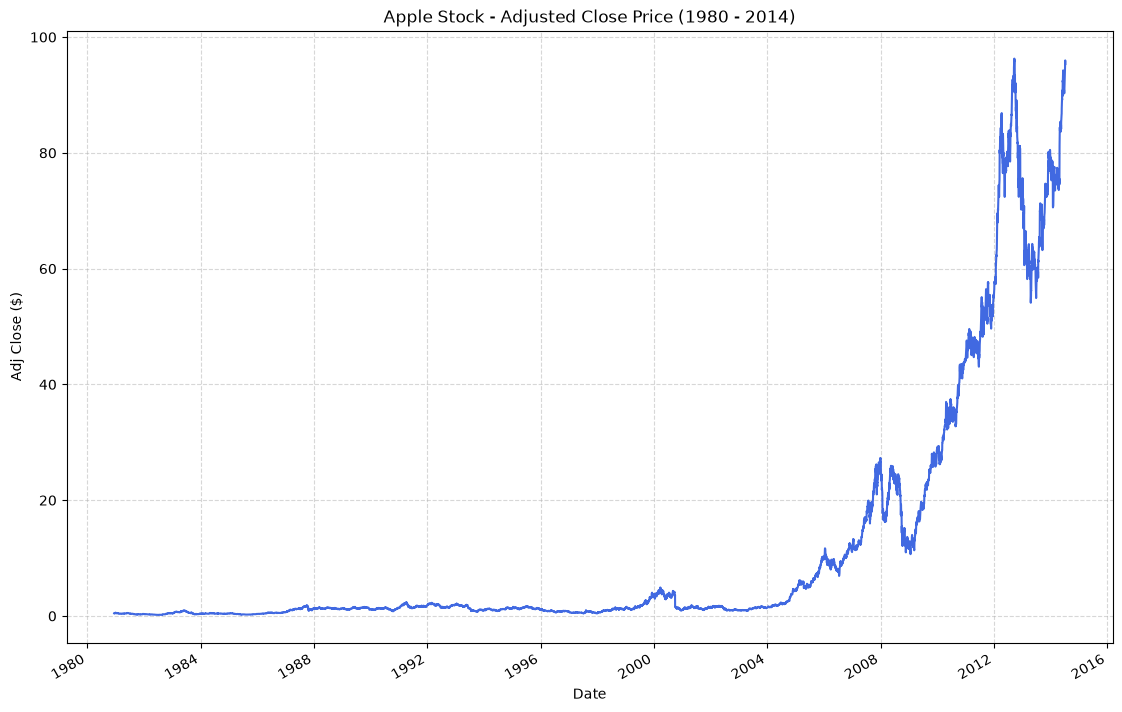

In [13]:
plt.figure(figsize=(13.5, 9))
apple['Adj Close'].plot(title="Apple Stock - Adjusted Close Price (1980 - 2014)", color="royalblue")
plt.xlabel("Date")
plt.ylabel("Adj Close ($)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()



### Objetivo
Cargar, limpiar, indexar, remuestrear y visualizar la serie temporal histórica del precio de las acciones de Apple (`1980–2014`) utilizando `pandas` y `matplotlib`.

### Explicación
* **Pasos 1–4 (Carga e Inspección):** Cargamos el archivo CSV directamente desde GitHub mediante `pd.read_csv()` e inspeccionamos las primeras filas con `head()`. Al revisar `dtypes` comprobamos que la columna `Date` se lee inicialmente como texto plano (`object`).
* **Pasos 5–6 (Indexación de Series Temporales):** Convertir `apple['Date']` con `pd.to_datetime()` habilita las operaciones temporales. Establecer `Date` como índice del DataFrame mediante `set_index('Date')` transforma la tabla en un `DatetimeIndex`.
* **Pasos 7–8 (Validación y Ordenación):** `apple.index.is_unique` devuelve `True`, confirmando que no existen días duplicados. Dado que el dataset original empieza por la fecha más reciente (`2014`), `sort_index(ascending=True)` reordena la línea temporal cronológicamente empezando desde el `1980-12-12`.
* **Pasos 9–11 (Remuestreo y Cálculo de Fechas):** Llamar a `resample('BME').last()` agrupa los registros diarios por el **último día hábil de cada mes** (*Business Month End*) y extrae el cierre de cada mes (`404` meses en total). Restar `apple.index.min()` a `apple.index.max()` calcula el intervalo exacto de `12.261` días naturales.
* **Paso 12 (Visualización):** Inicializamos un lienzo con `plt.figure(figsize=(13.5, 9))` y graficamos la serie `Adj Close` para visualizar el crecimiento histórico del precio de la acción de Apple.

